# Tiamat — Avaliação final no teste reservado

Estimar o desempenho do pipeline já congelado em partidas ainda não usadas para escolher o modelo.

O notebook avalia apenas o escolhido e o Dummy de referência. O pipeline permanece ajustado no treino; não há reajuste em `train + val`. Não use esses resultados para trocar modelo, limiar, atributos ou hiperparâmetros. Eles encerram esta execução experimental.


In [ ]:
from pathlib import Path
import hashlib
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 210906
LANCE = 40
MIN_CONFIGURACOES = 100
MODELOS = ['Regressao_Logistica', 'Random_Forest', 'Gradient_Boosting', 'XGBoost', 'SVM']
ATRIBUTOS = [
    'rank_b', 'rank_w', 'komi', 'handicap',
    'maior_grupo_b', 'maior_grupo_w',
    'liberdades_maior_grupo_b', 'liberdades_maior_grupo_w',
    'pedras_em_jogo_b', 'pedras_em_jogo_w',
    'pedras_capturadas_por_b', 'pedras_capturadas_por_w',
    'distancia_media_tengen_b', 'distancia_media_tengen_w',
    'quantidade_grupos_b', 'quantidade_grupos_w',
    'tamanho_medio_grupos_b', 'tamanho_medio_grupos_w',
    'liberdades_medias_grupos_b', 'liberdades_medias_grupos_w',
    'grupos_em_atari_b', 'grupos_em_atari_w',
    'pedras_em_atari_b', 'pedras_em_atari_w'
]
CANDIDATOS = [Path('data/piloto_final/lance_040.csv'),
    Path('data/piloto_corrigido/lance_040.csv'), Path('data/piloto/lance_040.csv'),
    Path('data/processed/lance_040.csv'), Path('lance_040.csv')]
ARQUIVO_CSV = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO_CSV is None:
    raise FileNotFoundError('Ajuste CANDIDATOS para localizar o mesmo CSV usado no notebook 03.')
PASTA = Path('results/lance_040')
PASTA.mkdir(parents=True, exist_ok=True)
FIGURAS = PASTA / 'figuras'
FIGURAS.mkdir(exist_ok=True)

def sha256_arquivo(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def ler_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def salvar_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        allow_nan=False), encoding='utf-8')

def carregar_dados(split):
    dados = pd.read_csv(ARQUIVO_CSV)
    dados = dados.loc[dados['split'].eq(split)].copy()
    if not len(dados):
        raise ValueError(f'Conjunto {split} vazio.')
    assert dados.game_id.is_unique
    assert dados.lance.eq(LANCE).all()
    assert dados.vencedor.isin(['B', 'W']).all()
    return dados

def separar_xy(dados):
    X = dados[ATRIBUTOS].apply(pd.to_numeric, errors='raise')
    y = dados.vencedor.map({'B': 0, 'W': 1}).astype(int)
    assert not np.isinf(X.to_numpy()).any()
    return X, y

def pontuacoes(modelo, X):
    if hasattr(modelo, 'predict_proba'):
        classe_w = list(modelo.classes_).index(1)
        return modelo.predict_proba(X)[:, classe_w], 'probabilidade_W'
    return np.asarray(modelo.decision_function(X)).ravel(), 'margem_W'

def metricas_predicoes(y, pred, score):
    y = np.asarray(y)
    return {'n': int(len(y)), 'accuracy': float(accuracy_score(y, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y, pred)),
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)),
        'roc_auc': float(roc_auc_score(y, score)) if len(np.unique(y)) == 2 else np.nan}

def avaliar_modelo(modelo, dados):
    X, y = separar_xy(dados)
    pred = modelo.predict(X)
    score, tipo = pontuacoes(modelo, X)
    tabela = pd.DataFrame({'game_id': dados.game_id.to_numpy(),
        'y_real': y.to_numpy(), 'y_pred': pred, 'score_W': score,
        'tipo_score': tipo, 'acertou': pred == y.to_numpy()})
    return metricas_predicoes(y, pred, score), tabela

def carregar_estudos():
    estudos, linhas = {}, []
    for nome in MODELOS:
        db = (PASTA / f'optuna_{nome}.db').resolve()
        distintos = completos = 0
        melhor = np.nan
        if db.exists():
            estudo = optuna.load_study(study_name=f'tiamat_lance40_{nome}',
                storage=f'sqlite:///{db.as_posix()}')
            estudos[nome] = estudo
            trials = [t for t in estudo.trials
                if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None]
            completos = len(trials)
            distintos = len({json.dumps(t.params, sort_keys=True) for t in trials})
            if completos:
                melhor = float(estudo.best_value)
        resumo_path = PASTA / f'resumo_{nome}.json'
        if resumo_path.exists():
            resumo = ler_json(resumo_path)
            if (resumo.get('seed') != SEED or resumo.get('lance') != LANCE
                    or resumo.get('folds') != 5):
                raise ValueError(f'Resumo de {nome} incompatível com o protocolo do 03 antigo.')
        linhas.append({'modelo': nome, 'configuracoes_distintas': distintos,
            'trials_completos': completos, 'roc_auc_cv': melhor,
            'pronto': distintos >= MIN_CONFIGURACOES})
    return estudos, pd.DataFrame(linhas)

def carregar_selecionado():
    selecao = ler_json(PASTA / 'selecao_congelada.json')
    if selecao.get('origem') != '03_antigo':
        raise ValueError('A seleção existente não foi produzida por esta sequência compatível.')
    if selecao['sha256_csv'] != sha256_arquivo(ARQUIVO_CSV):
        raise ValueError('O CSV foi alterado após a seleção. Preserve os dados desta execução.')
    path = PASTA / selecao['arquivo_modelo']
    if selecao['sha256_modelo'] != sha256_arquivo(path):
        raise ValueError('O modelo selecionado foi alterado após o congelamento.')
    return joblib.load(path), selecao

print('CSV:', ARQUIVO_CSV, '| resultados:', PASTA)
print('SEED:', SEED, '| 24 atributos | compatível com o notebook 03 original')


CSV: data\piloto_final\lance_040.csv | resultados: results\lance_040
SEED: 210906 | 24 atributos | compatível com o notebook 03 original


## 1. Verificar a escolha antes de abrir o teste


In [2]:
def executar_teste_final(repeticoes=2000):
    modelo, selecao = carregar_selecionado()
    assinatura_selecao = sha256_arquivo(PASTA / 'selecao_congelada.json')
    arquivo = PASTA / 'avaliacao_final_teste.json'
    if arquivo.exists():
        resultado = ler_json(arquivo)
        if resultado['assinatura_selecao'] != assinatura_selecao:
            raise ValueError('A avaliação salva pertence a outra seleção.')
        for nome, chave in [('predicoes_teste_final.csv', 'sha256_predicoes'),
                            ('predicoes_teste_dummy.csv', 'sha256_predicoes_dummy')]:
            if sha256_arquivo(PASTA / nome) != resultado[chave]:
                raise ValueError(f'As predições salvas foram alteradas: {nome}.')
        print('Reutilizando a avaliação final já registrada.')
        return resultado
    dummy_path = PASTA / selecao['arquivo_dummy']
    if sha256_arquivo(dummy_path) != selecao['sha256_dummy']:
        raise ValueError('O Dummy foi alterado após a seleção.')
    dummy = joblib.load(dummy_path)
    teste = carregar_dados('test')
    treino = carregar_dados('train')
    val = carregar_dados('val')
    assert set(teste.game_id).isdisjoint(treino.game_id)
    assert set(teste.game_id).isdisjoint(val.game_id)
    metricas, pred = avaliar_modelo(modelo, teste)
    metricas_dummy, pred_dummy = avaliar_modelo(dummy, teste)
    pred.to_csv(PASTA / 'predicoes_teste_final.csv', index=False)
    pred_dummy.to_csv(PASTA / 'predicoes_teste_dummy.csv', index=False)
    rng = np.random.default_rng(SEED)
    classes = [np.flatnonzero(pred.y_real.to_numpy() == classe) for classe in [0, 1]]
    if any(len(indices) == 0 for indices in classes):
        raise ValueError('O bootstrap estratificado exige ambas as classes no teste.')
    amostras = {m: [] for m in ['accuracy', 'balanced_accuracy', 'f1_macro', 'roc_auc']}
    for _ in range(repeticoes):
        indices = np.concatenate([rng.choice(ids, size=len(ids), replace=True) for ids in classes])
        sub = pred.iloc[indices]
        valores = metricas_predicoes(sub.y_real, sub.y_pred, sub.score_W)
        for m in amostras:
            amostras[m].append(valores[m])
    intervalos = {m: {'estimativa': metricas[m],
        'inferior_95': float(np.quantile(v, 0.025)),
        'superior_95': float(np.quantile(v, 0.975))} for m, v in amostras.items()}
    resultado = {'modelo': selecao['modelo'], 'ajustado_em': 'train',
        'assinatura_selecao': assinatura_selecao, 'n_teste': len(teste),
        'metricas': metricas, 'dummy': metricas_dummy,
        'intervalos_bootstrap': intervalos, 'repeticoes_bootstrap': repeticoes,
        'sha256_predicoes': sha256_arquivo(PASTA / 'predicoes_teste_final.csv'),
        'sha256_predicoes_dummy': sha256_arquivo(PASTA / 'predicoes_teste_dummy.csv'),
        'limites_bootstrap': 'Predições fixas, classes fixas; assume partidas independentes; não cobre busca nem reajuste.'}
    salvar_json(arquivo, resultado)
    return resultado

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

PRONTO = (PASTA / 'selecao_congelada.json').exists()
if PRONTO:
    modelo, selecao = carregar_selecionado()
    display(pd.Series({k: selecao[k] for k in ['modelo', 'regra', 'limiar', 'ajustado_em', 'n_treino']},
        name='protocolo congelado').to_frame())
else:
    print('Execute o notebook 04 para congelar a seleção.')


,protocolo congelado
modelo,Random_Forest
regra,Maior ROC-AUC em val; empate: ROC-AUC CV; depo...
limiar,0.5
ajustado_em,train
n_treino,4612


## 2. Executar uma única avaliação

Depois de terminar a seleção e o diagnóstico, altere `EXECUTAR_TESTE_FINAL` para `True` para a execução do teste. O resultado é salvo. Ao executar novamente com a mesma seleção, o notebook usa as predições já salvas, sem refazer a avaliação.

Os intervalos bootstrap reamostram as predições fixas, mantendo as contagens das duas classes. Descrevem a incerteza amostral sob a hipótese de partidas independentes; não incorporam o retreinamento, a busca de hiperparâmetros nem a dependência entre jogadores.


In [3]:
EXECUTAR_TESTE_FINAL = True
REPETICOES_BOOTSTRAP = 2000
resultado_final = None
caminho_final = PASTA / 'avaliacao_final_teste.json'
if PRONTO and (EXECUTAR_TESTE_FINAL or caminho_final.exists()):
    resultado_final = executar_teste_final(repeticoes=REPETICOES_BOOTSTRAP)
    display(pd.DataFrame({'modelo_selecionado': resultado_final['metricas'],
        'Dummy_prior': resultado_final['dummy']}))
    intervalos = pd.DataFrame(resultado_final['intervalos_bootstrap']).T
    display(intervalos)
    intervalos.to_csv(PASTA / 'intervalos_teste.csv')
else:
    print('Teste ainda reservado. Habilite a execução somente após concluir a seleção.')


,modelo_selecionado,Dummy_prior
n,274.000000,274.000000
accuracy,0.558394,0.525547
balanced_accuracy,0.557425,0.500000
f1_macro,0.557398,0.344498
roc_auc,0.579167,0.500000


,estimativa,inferior_95,superior_95
accuracy,0.558394,0.500000,0.620438
balanced_accuracy,0.557425,0.498495,0.618323
f1_macro,0.557398,0.498486,0.618405
roc_auc,0.579167,0.513882,0.645943


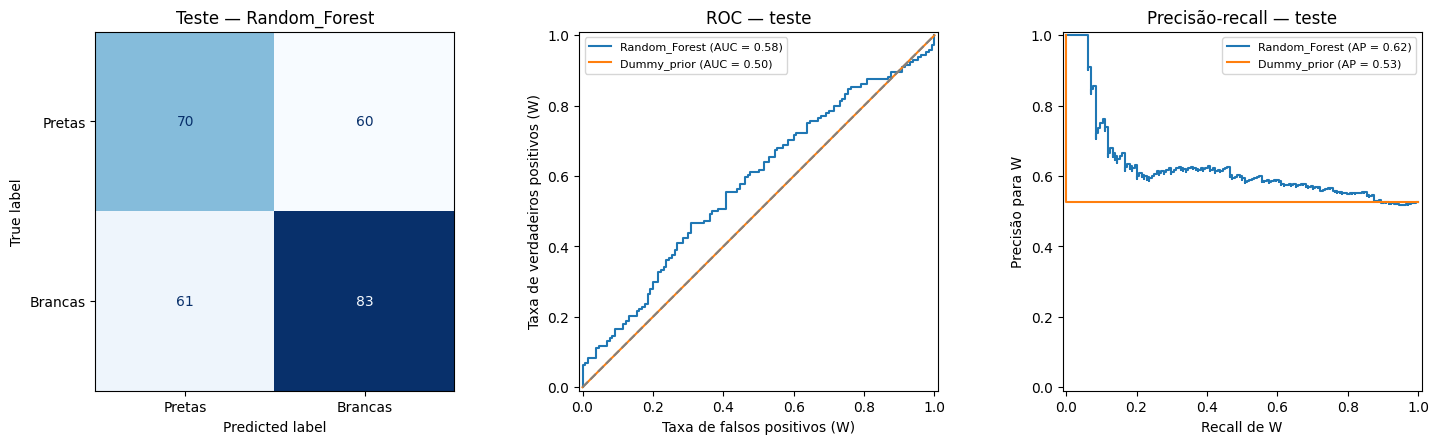

In [4]:
if resultado_final is not None:
    pred = pd.read_csv(PASTA / 'predicoes_teste_final.csv')
    dummy = pd.read_csv(PASTA / 'predicoes_teste_dummy.csv')
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    ConfusionMatrixDisplay.from_predictions(pred.y_real, pred.y_pred, labels=[0, 1],
        display_labels=['Pretas', 'Brancas'], ax=axes[0], colorbar=False, cmap='Blues')
    axes[0].set_title(f"Teste — {resultado_final['modelo']}")
    for nome, p in [(resultado_final['modelo'], pred), ('Dummy_prior', dummy)]:
        RocCurveDisplay.from_predictions(p.y_real, p.score_W, name=nome, ax=axes[1])
        PrecisionRecallDisplay.from_predictions(p.y_real, p.score_W, name=nome, ax=axes[2])
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    axes[1].set(xlabel='Taxa de falsos positivos (W)', ylabel='Taxa de verdadeiros positivos (W)', title='ROC — teste')
    axes[2].set(xlabel='Recall de W', ylabel='Precisão para W', title='Precisão-recall — teste')
    for ax in axes[1:]: ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIGURAS / '06_avaliacao_final.png', dpi=180); plt.show()


## Análise

Nas 274 partidas de teste, o Random Forest obteve ROC-AUC de 0,5792.  
O intervalo bootstrap de 95% foi de 0,5139 a 0,6459.  
A accuracy foi de 0,5584, contra 0,5255 do Dummy.  
A ROC-AUC ficou abaixo dos 0,6083 observados na validação.

## Conclusões e principais aprendizados

O ganho sobre o Dummy foi de 0,0792 em ROC-AUC.  
A discriminação foi modesta; o intervalo da balanced accuracy incluiu 0,5.  
O bootstrap pressupõe independência e não incorpora busca ou retreinamento.  
Novos ajustes exigem outra avaliação independente.

## Descrição do uso de IA neste trabalho

O ChatGPT auxiliou na avaliação e na comparação com o Dummy.  
Também apoiou o bootstrap estratificado, com 2.000 reamostragens.  
A interpretação utilizou as métricas e os intervalos registrados.  
O teste avaliou o pipeline previamente escolhido.


## Referências consultadas

- Cassar, D. R. *Criaturas Lendárias do Reino de Lumi e onde encontrá-las*, seção 4, Tiamat, pp. 7–9. Material da ATP-203 fornecido no projeto.
- [scikit-learn: prevenção de vazamento e pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: métricas de classificação](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [Optuna: estudos persistentes](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html).
- [Optuna: Study e estados dos trials](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html).
- [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [scikit-learn: dependência parcial](https://scikit-learn.org/stable/modules/partial_dependence.html).
- [scikit-learn: SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html).
- [XGBoost: hiperparâmetros](https://xgboost.readthedocs.io/en/stable/parameter.html).

Consulta: 11/11/2026. Complete a referência da fonte original dos SGFs com o endereço e a data de obtenção realmente utilizados.
